Gold notebook: RFM stands for recency, frequency, and monetary. This way we can see when they bought, how much they bought, and the value (quantity x price)

In [2]:
from pathlib import Path
import duckdb
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
DB_PATH = PROJECT_ROOT / "data" / "ltv.duckdb"

cols = ["Invoice", "Quantity", "InvoiceDate", "Price", "Customer_ID", "Country",
        "Customer_ID_Exists", "Cancelled_Order", "Return_Adjustment"]

with duckdb.connect(str(DB_PATH)) as con:
    silver = con.sql(f"SELECT {', '.join(cols)} FROM silver").df()

print(f"Silver rows loaded: {len(silver):,}")

Silver rows loaded: 1,067,371


In [3]:
with duckdb.connect(str(DB_PATH)) as con:
    silver = con.sql("""
        SELECT Invoice, InvoiceDate, Customer_ID, Quantity, Price,
               Customer_ID_Exists, Cancelled_Order, Return_Adjustment
        FROM silver
    """).df()

sales = silver[
    silver["Customer_ID_Exists"]
    & ~silver["Cancelled_Order"] #~ means NOT, so this is filtering out cancelled orders
    & ~silver["Return_Adjustment"] #~ means NOT, so this is filtering out returns/adjustments
    & (silver["Quantity"] > 0)
    & (silver["Price"] > 0)
].copy()
del silver

sales["line_total"] = sales["Quantity"] * sales["Price"]
print(f"Usable sales rows: {len(sales):,}")
print(f"Customers: {sales['Customer_ID'].nunique():,}")

Usable sales rows: 805,549
Customers: 5,878


In [ ]:
sales["InvoiceDate"] = pd.to_datetime(sales["InvoiceDate"])
snapshot = sales["InvoiceDate"].max() + pd.Timedelta(days=1)   #as of date: day after the last invoice in the data

gold = sales.groupby("Customer_ID").agg(
    first_purchase=("InvoiceDate", "min"),
    last_purchase=("InvoiceDate", "max"),
    frequency=("Invoice", "nunique"),
    monetary=("line_total", "sum"),
).reset_index()

gold["recency_days"] = (snapshot - gold["last_purchase"]).dt.days
gold["tenure_days"] = (snapshot - gold["first_purchase"]).dt.days
gold["first_purchase_month"] = gold["first_purchase"].dt.to_period("M").astype(str)

gold["first_purchase"] = gold["first_purchase"].dt.date
gold["last_purchase"] = gold["last_purchase"].dt.date

print(f"Snapshot date: {snapshot.date()}")
print(gold.describe().round(1))
gold.head()

Snapshot date: 2011-12-10
       Customer_ID  frequency  monetary  recency_days  tenure_days
count       5878.0     5878.0    5878.0        5878.0       5878.0
mean       15315.3        6.3    3018.6         201.9        475.3
std         1715.6       13.0   14737.7         209.4        223.1
min        12346.0        1.0       3.0           1.0          1.0
25%        13833.2        1.0     348.8          26.0        314.0
50%        15314.5        3.0     898.9          96.0        531.0
75%        16797.8        7.0    2307.1         380.0        669.0
max        18287.0      398.0  608821.6         739.0        739.0


,Customer_ID,first_purchase,last_purchase,frequency,monetary,recency_days,tenure_days,first_purchase_month
0,12346,2009-12-14,2011-01-18,12,77556.46,326,726,2009-12
1,12347,2010-10-31,2011-12-07,8,5633.32,3,405,2010-10
2,12348,2010-09-27,2011-09-25,5,2019.40,76,439,2010-09
3,12349,2010-04-29,2011-11-21,4,4428.69,19,590,2010-04
4,12350,2011-02-02,2011-02-02,1,334.40,311,311,2011-02


In [14]:
# Demo: save the final gold table to a local CSV, then re-read it with a relative path
EXPORT_DIR = PROJECT_ROOT / "data" / "exports"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
gold_csv = EXPORT_DIR / "gold_customers.csv"

gold.to_csv(gold_csv, index=False)                 # save

check = pd.read_csv(gold_csv)                      # re-read
print(f"Saved to: {gold_csv.relative_to(PROJECT_ROOT)}")
print(f"Re-read {len(check):,} rows, {check.shape[1]} columns")
check.head()

Saved to: data/exports/gold_customers.csv
Re-read 5,878 rows, 8 columns


,Customer_ID,first_purchase,last_purchase,frequency,monetary,recency_days,tenure_days,first_purchase_month
0,12346,2009-12-14,2011-01-18,12,77556.46,326,726,2009-12
1,12347,2010-10-31,2011-12-07,8,5633.32,3,405,2010-10
2,12348,2010-09-27,2011-09-25,5,2019.40,76,439,2010-09
3,12349,2010-04-29,2011-11-21,4,4428.69,19,590,2010-04
4,12350,2011-02-02,2011-02-02,1,334.40,311,311,2011-02


## What do our customers look like? (Recency, Frequency, Spend)
**Days since last purchase:** Most customers bought recently. Half of them bought within the last 96 days of the data, and a quarter bought within the last 26 days. But about a quarter haven't bought in over a year (380+ days). The small bump around 400 days looks like customers who bought during the November 2010 rush and never came back.  
**Number of orders:** Most customers don't order a lot. 27.6% only ordered once, 55% ordered 3 times or fewer, and 85% ordered 10 times or fewer. Only about 5% of customers ordered more than 20 times, and a few ordered hundreds of times. That small group is probably wholesale buyers.  
**Total spend:** Spend is really spread out. The typical customer spent around $900, but the average is over $3,000 because a few customers spent hundreds of thousands. We used a log scale on this chart so the whole range is readable, so each step to the right is 10x more spend.  
**Takeaway:** We have a lot of casual, low frequency buyers and a small group of heavy buyers. We can't treat all customers the same.

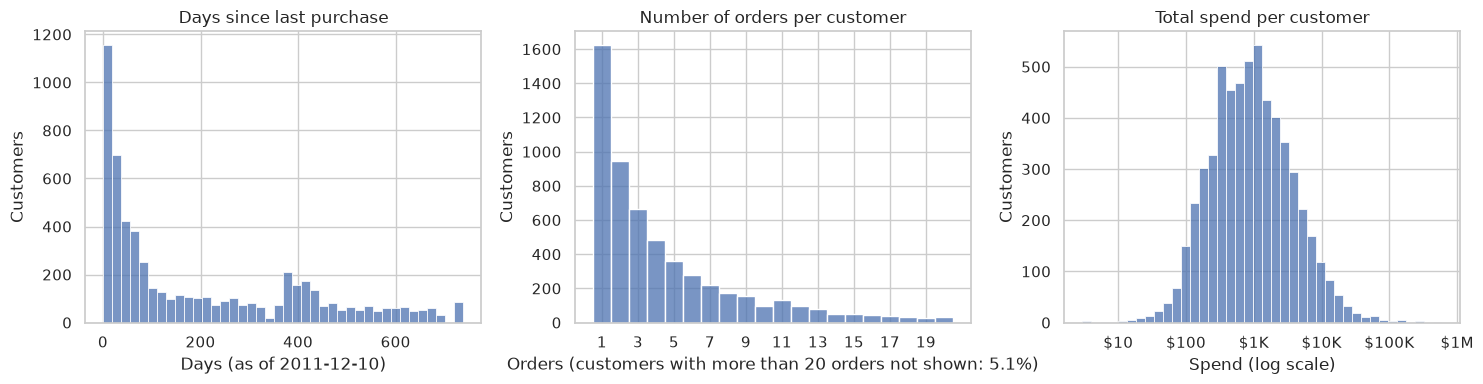

One-time customers: 27.6%
1 order(s) or fewer: 27.6%
2 order(s) or fewer: 43.7%
3 order(s) or fewer: 55.0%
5 order(s) or fewer: 69.4%
10 order(s) or fewer: 85.1%


In [22]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
sns.set_theme(style="whitegrid")

def dollars(x, _):
    if x >= 1e6: return f"${x/1e6:.0f}M"
    if x >= 1e3: return f"${x/1e3:.0f}K"
    return f"${x:.0f}"

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1) Recency (normal scale)
sns.histplot(gold["recency_days"], bins=40, ax=axes[0])
axes[0].set_title("Days since last purchase")
axes[0].set_xlabel("Days (as of 2011-12-10)")

# 2) Frequency (normal scale, whole-number bars, zoomed to where most customers are)
cap = 20
share_above = (gold["frequency"] > cap).mean()
sns.histplot(gold.loc[gold["frequency"] <= cap, "frequency"], discrete=True, ax=axes[1])
axes[1].set_title("Number of orders per customer")
axes[1].set_xlabel(f"Orders (customers with more than {cap} orders not shown: {share_above:.1%})")
axes[1].set_xticks(range(1, cap + 1, 2))

# 3) Monetary (log scale, because spend runs from $3 to $600K+)
sns.histplot(gold["monetary"], bins=40, log_scale=True, ax=axes[2])
axes[2].set_title("Total spend per customer")
axes[2].set_xlabel("Spend (log scale)")
axes[2].xaxis.set_major_formatter(FuncFormatter(dollars))

for ax in axes:
    ax.set_ylabel("Customers")

plt.tight_layout()
plt.show()

print(f"One-time customers: {(gold['frequency'] == 1).mean():.1%}")
for n in [1, 2, 3, 5, 10]:
    print(f"{n} order(s) or fewer: {(gold['frequency'] <= n).mean():.1%}")

## How much revenue comes from our best customers?
We sorted customers from highest spender to lowest and tracked how much of the total revenue they add up to. The gray dashed line is what it would look like if every customer spent the same amount. The blue line is what actually happens.  
The blue line is way above the gray line, so a small group of customers drives most of the revenue. The top 20% of customers account for **[X]%** of revenue, and the top 1% account for **[Y]%**. The bottom half of customers only account for **[Z]%**.  
**Takeaway:** Losing a few top customers hurts a lot more than losing a lot of small ones. Our retention efforts should start with the top spenders.  
*Note: revenue here is before returns and cancellations.*

Top 20% of customers = 77.2% of revenue


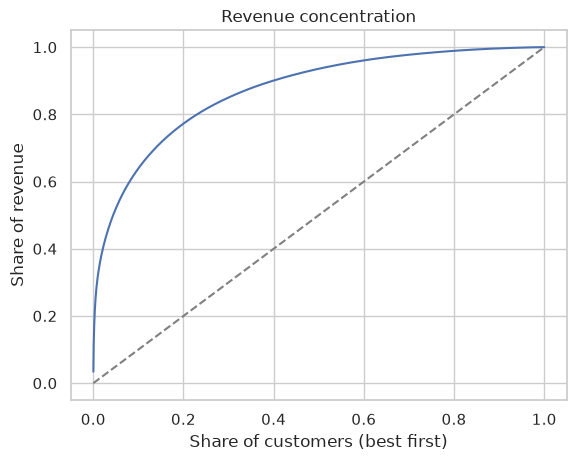

In [23]:
g = gold.sort_values("monetary", ascending=False).reset_index(drop=True)
g["cumulative_revenue_share"] = g["monetary"].cumsum() / g["monetary"].sum()
g["customer_share"] = (g.index + 1) / len(g)

top20 = g.loc[g["customer_share"] <= 0.20, "monetary"].sum() / g["monetary"].sum()
print(f"Top 20% of customers = {top20:.1%} of revenue")

plt.plot(g["customer_share"], g["cumulative_revenue_share"])
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("Share of customers (best first)")
plt.ylabel("Share of revenue")
plt.title("Revenue concentration")
plt.show()

## When do we make our money?
Monthly revenue builds from September, peaks in **November** both years at roughly $1.1 to $1.2 million, and then drops off. That's about double a normal month, which sits around $0.5 to $0.7 million. The rest of the year is pretty flat.  
The drop at the very end of the line is only because the data stops on December 9, so December 2011 is an incomplete month. It isn't a real crash.  
2010 and 2011 look about the same, so we see strong seasonality but no clear growth between the two years.  
**Takeaway:** Our business depends on the fall season. Stock, staffing, and campaigns need to be ready by September, and customers we bring in during that window are worth more than the same customers in a slow month.

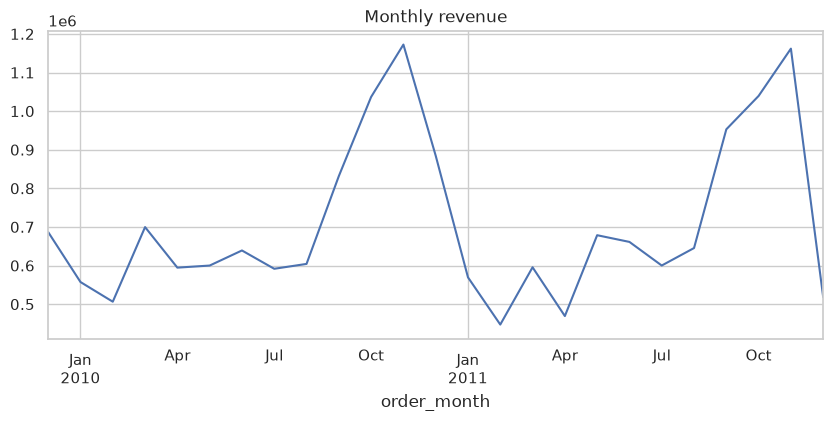

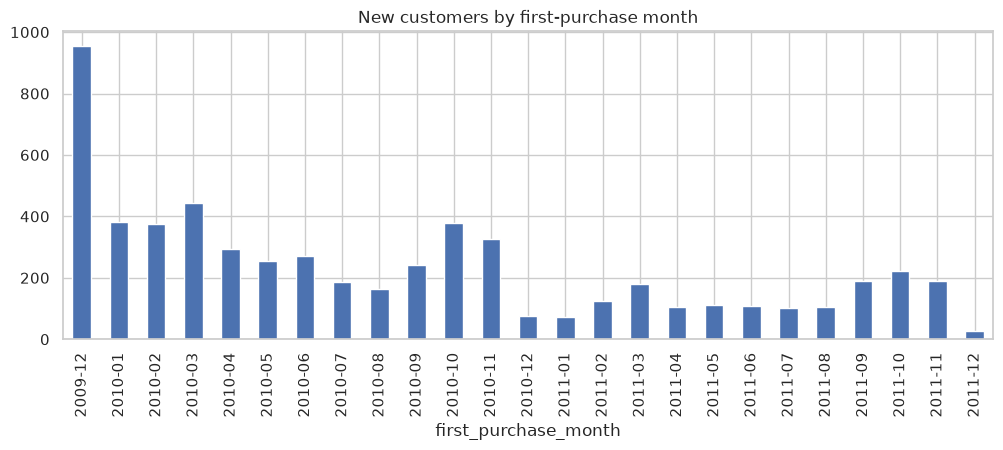

In [24]:
sales["order_month"] = sales["InvoiceDate"].dt.to_period("M")
monthly = sales.groupby("order_month")["line_total"].sum()
monthly.plot(figsize=(10, 4), title="Monthly revenue")
plt.show()

gold["first_purchase_month"].value_counts().sort_index().plot(
    kind="bar", figsize=(12, 4), title="New customers by first-purchase month")
plt.show()

## Do customers keep coming back after their first purchase?
Each row is a group of customers who made their first purchase in the same month. Each column is the number of months after that first purchase. The color shows what share of that group bought again in that specific month. Month 0 is always 100% because that's the first purchase.  
Right after month 0, the color drops off fast. In a typical later month, only about 10 to 20% of a cohort buys. That's normal for a store where people don't buy on a schedule, but it means most new customers don't become regulars.  
The darker diagonal bands show the seasonal effect again. Customers from lots of different cohorts all come back around November 2010, which matches the revenue peak.  
A few things to keep in mind when reading it:
- The top row (2009-12) looks stronger because it includes every customer who already existed when the data starts. They aren't new customers, so we shouldn't compare other cohorts against it.
- The empty triangle in the bottom right is just missing data. Recent cohorts haven't had time to be observed yet.
- A light cell doesn't always mean a customer left. They might just skip a month and come back later. Figuring out who is gone versus who is just between purchases is what the BG/NBD model will do.

**Takeaway:** Most new customers buy once or twice, a smaller group keeps coming back, and a lot of the returns happen in the Sep to Nov season.

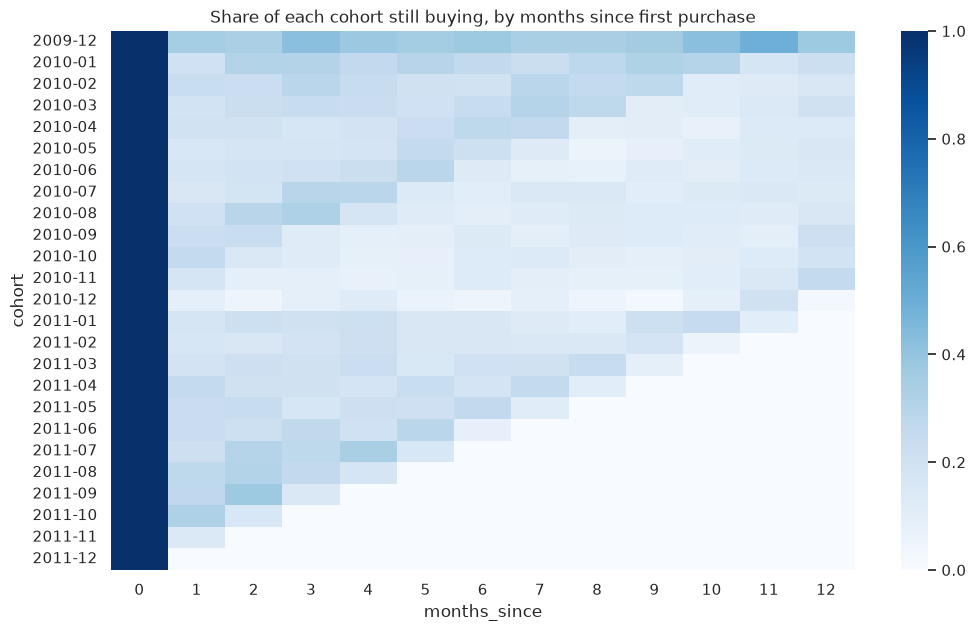

In [25]:
first = sales.groupby("Customer_ID")["order_month"].min().rename("cohort")
act = (sales.merge(first, on="Customer_ID")[["Customer_ID", "cohort", "order_month"]]
            .drop_duplicates())
act["months_since"] = (act["order_month"] - act["cohort"]).apply(lambda d: d.n)

ret = act.groupby(["cohort", "months_since"])["Customer_ID"].nunique().unstack(fill_value=0)
ret_pct = ret.div(ret[0], axis=0).iloc[:, :13]   # first 12 months

plt.figure(figsize=(12, 7))
sns.heatmap(ret_pct, cmap="Blues", vmin=0, vmax=1)
plt.title("Share of each cohort still buying, by months since first purchase")
plt.show()